# Land-cover segmentation — a compact residual experiment

This notebook follows the same order as `03_baseline.ipynb`: **load data → build a model → train → evaluate → inspect predictions**.

The model is a **small residual CNN with atrous spatial pyramid pooling (ASPP)**. Residual connections help information flow; parallel dilated convolutions gather context at different scales; a shallow skip connection restores detail. This is a custom educational model inspired by DeepLab, **not an implementation of DeepLabV3+**.

Compared with your baseline, the architecture and training objective change: we use residual blocks, multiscale context, GroupNorm, Cross-Entropy + soft Dice, AdamW and a validation-driven learning-rate scheduler. This is an alternative complete configuration, not a controlled single-factor ablation. More components do not guarantee better accuracy.

**Default run:** two short epochs on 12 training images and six validation images. This is a pipeline demonstration, not a completed research experiment. Test regions stay untouched. Preprocessing remains exactly the existing RGB/255, 512×512 resize and Unknown=255.

Only installed packages are used: **PyTorch** for modelling/training, **NumPy/pandas** for metrics and evidence, **Seaborn/Matplotlib** for plots, and **Pillow** through the existing loader. No downloads, installations, uploads or W&B setup are required.

## 1. Imports and experiment settings

All settings are here. The small sample counts make Run All practical on CPU. Keep these values for the demonstration; inspect alignment and complete the two-image overfit check before planning a full run.

A seed makes the setup repeatable within the recorded environment, not identical across all hardware and PyTorch versions.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata as metadata
import json
import random
import sys
import time
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from IPython.display import display

SEED, EPOCHS, BATCH_SIZE = 42, 2, 2
TRAIN_IMAGES, VALID_IMAGES = 12, 6
WIDTH, LEARNING_RATE, DICE_WEIGHT = 16, 1e-3, 0.5
IGNORE, NUM_CLASSES = 255, 8
CLASS_NAMES = ["Bareland", "Rangeland", "Developed Space", "Road",
               "Tree", "Water", "Agriculture Land", "Building"]
COLORS = np.array([[128, 0, 0], [0, 255, 36], [148, 148, 148], [255, 255, 255],
                   [34, 97, 38], [0, 69, 255], [75, 181, 73], [222, 31, 7]], dtype=np.uint8)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.dataset import LandCoverDataset, prepare_pair

run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
OUT = ROOT / "results/vibecode-test1/residual_aspp" / run_name
OUT.mkdir(parents=True)
print(f"Device: {device} | PyTorch: {torch.__version__} | Output: {OUT.relative_to(ROOT)}")

Device: cpu | PyTorch: 2.15.0+cpu | Output: results\vibecode-test1\residual_aspp\20261121T121156Z_211871


## 2. Reuse the existing splits and preprocessing

The official mask IDs 1–8 become model IDs 0–7; raw 0 becomes ignored target 255. The class palette matches the existing EDA and the official OpenEarthMap code.

We preserve the saved geographical partitions and sample within them. No test images are loaded. The earlier preprocessing notebook contains the full integrity investigation; here we retain only path, pairing, split and batch checks. These checks do not establish the absence of overlapping tiles or annotation errors.

In [2]:
manifest_path = ROOT / "results/tables/split_manifest.csv"
pairs = pd.read_csv(manifest_path)
for column in ["image", "mask"]:
    pairs[column] = pairs[column].map(
        lambda value: (ROOT / "notebooks" / Path(str(value).replace(chr(92), "/"))).resolve())
    assert pairs[column].map(Path.is_file).all()
    assert not pairs[column].duplicated().any()
assert pairs.groupby("region").split.nunique().eq(1).all()
assert all(r.image.name == r.mask.name and
           r.image.parent.parent.name == r.mask.parent.parent.name == r.region
           for r in pairs.itertuples())
display(pairs.groupby("split").agg(images=("image", "size"), regions=("region", "nunique")))

# One image per region in this small demonstration; the original splits are unchanged.
train_pairs = pairs.query("split == 'train'").groupby("region").head(1).sample(TRAIN_IMAGES, random_state=SEED).reset_index(drop=True)
val_pairs = pairs.query("split == 'validation'").groupby("region").head(1).sample(VALID_IMAGES, random_state=SEED).reset_index(drop=True)
test_pairs = pairs.query("split == 'test'").reset_index(drop=True)
train_data = LandCoverDataset(train_pairs)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
images, masks = next(iter(train_loader))
train_loader.generator.manual_seed(SEED)
assert images.shape == (BATCH_SIZE, 3, 512, 512) and images.dtype == torch.float32
assert masks.shape == (BATCH_SIZE, 512, 512) and masks.dtype == torch.int64
assert 0 <= images.min() <= images.max() <= 1
assert torch.isin(masks, torch.tensor([*range(8), IGNORE])).all()
pd.concat([train_pairs, val_pairs]).to_csv(OUT / "demo_manifest.csv", index=False)
print(f"Demo: {len(train_pairs)} training images, {len(val_pairs)} validation images. Test: reserved.")

,images,regions
split,,
test,470,12
train,1942,52
validation,275,11


Demo: 12 training images, 6 validation images. Test: reserved.


## 3. Check alignment visually

Black mask pixels are ignored. Inspect roads, building boundaries and water edges in the overlay. Correct shapes alone do not prove correct alignment. Resizing to 512×512 can remove small details.

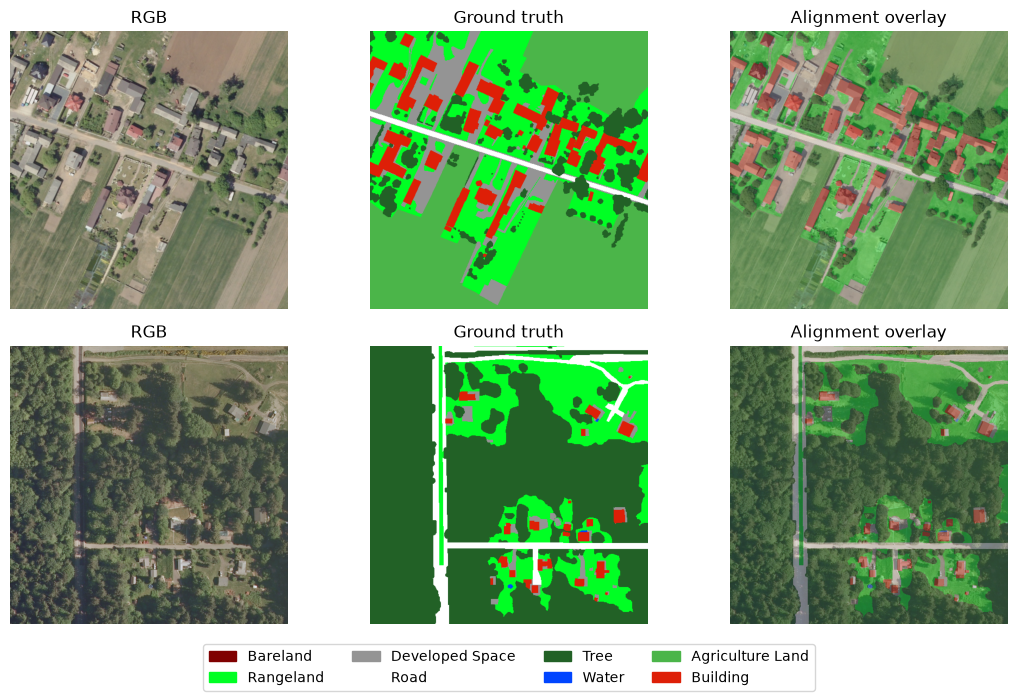

In [3]:
def colorize(mask):
    labels = np.asarray(mask)
    rgb = np.zeros((*labels.shape, 3), dtype=np.uint8)
    valid = (labels >= 0) & (labels < NUM_CLASSES)
    rgb[valid] = COLORS[labels[valid]]
    return rgb

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for row in range(2):
    rgb = images[row].permute(1, 2, 0).numpy()
    axes[row, 0].imshow(rgb)
    axes[row, 1].imshow(colorize(masks[row]))
    axes[row, 2].imshow(rgb)
    axes[row, 2].imshow(colorize(masks[row]), alpha=0.35)
    for axis, title in zip(axes[row], ["RGB", "Ground truth", "Alignment overlay"]):
        axis.set_title(title)
        axis.axis("off")
fig.legend(handles=[Patch(color=c / 255, label=n) for c, n in zip(COLORS, CLASS_NAMES)],
           loc="lower center", ncol=4)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(OUT / "alignment.png", dpi=110)
plt.show()

## 4. Residual blocks

Each block learns a correction to its input: **output = activation(features + shortcut)**. A 1×1 shortcut matches channels and resolution when required.

GroupNorm works without batch statistics. The `conv_block` helper is just convolution → GroupNorm → ReLU; it introduces no hidden framework.

In [4]:
def conv_block(in_channels, out_channels, kernel=3, stride=1, dilation=1):
    padding = dilation * (kernel // 2)
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel, stride=stride,
                  padding=padding, dilation=dilation, bias=False),
        nn.GroupNorm(4, out_channels),
        nn.ReLU())


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(in_channels, out_channels, stride=stride),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels))
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False)

    def forward(self, x):
        return F.relu(self.features(x) + self.shortcut(x))

## 5. Multiscale context and a small decoder

At 1/8 resolution, three branches use dilation rates 1, 2 and 4. A fourth branch pools the whole feature map for global context. The decoder combines these features with a shallow 1/2-resolution skip connection.

For a 512×512 input: **512 → 256 → 128 → 64 → context → 256 → 512**. The final layer returns eight logits per pixel. This adds architectural ideas without making the network as wide as the U-Net64 baseline.

In [5]:
class ResidualASPP(nn.Module):
    def __init__(self, width=16):
        super().__init__()
        self.stem = conv_block(3, width, stride=2)
        self.encoder = nn.Sequential(
            ResidualBlock(width, width * 2, stride=2),
            ResidualBlock(width * 2, width * 4, stride=2),
            ResidualBlock(width * 4, width * 4))
        self.branches = nn.ModuleList([
            conv_block(width * 4, width, dilation=rate) for rate in [1, 2, 4]])
        self.global_context = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Conv2d(width * 4, width, 1), nn.ReLU())
        self.fuse = conv_block(width * 4, width * 2, kernel=1)
        self.decoder = ResidualBlock(width * 3, width)
        self.head = nn.Conv2d(width, NUM_CLASSES, 1)

    def forward(self, x):
        original_size = x.shape[-2:]
        detail = self.stem(x)
        features = self.encoder(detail)
        context = [branch(features) for branch in self.branches]
        pooled = F.interpolate(self.global_context(features), size=features.shape[-2:],
                               mode="bilinear", align_corners=False)
        context = self.fuse(torch.cat(context + [pooled], dim=1))
        context = F.interpolate(context, size=detail.shape[-2:], mode="bilinear", align_corners=False)
        logits = self.head(self.decoder(torch.cat([detail, context], dim=1)))
        return F.interpolate(logits, size=original_size, mode="bilinear", align_corners=False)

In [6]:
model = ResidualASPP(WIDTH).to(device)
model.eval()
with torch.no_grad():
    logits = model(images[:1].to(device))
assert logits.shape == (1, 8, 512, 512) and torch.isfinite(logits).all()
parameter_count = sum(p.numel() for p in model.parameters())
print("Input:", tuple(images[:1].shape), "| Output:", tuple(logits.shape))
print(f"Trainable parameters: {parameter_count:,}")

Input: (1, 3, 512, 512) | Output: (1, 8, 512, 512)
Trainable parameters: 187,592


## 6. Loss and metrics

**Loss = Cross-Entropy + 0.5 × soft Dice loss.** Cross-Entropy scores each valid pixel; soft Dice encourages class overlap. For the loss, Dice averages classes present in the batch target; Cross-Entropy also penalizes predictions of absent classes. Unknown pixels contribute to neither term.

**Evaluation uses hard predictions:** sum confusion counts over the entire evaluated subset, then calculate per-class IoU/Dice. A class absent from both truth and prediction is NaN and excluded from the mean; a falsely predicted absent class scores zero. Always inspect support as well as the mean.

In [7]:
def segmentation_loss(logits, target):
    valid = target != IGNORE
    if not valid.any():
        return logits.sum() * 0
    ce = F.cross_entropy(logits, target, ignore_index=IGNORE, reduction="sum") / valid.sum()
    labels = target.masked_fill(~valid, 0)
    one_hot = F.one_hot(labels, NUM_CLASSES).permute(0, 3, 1, 2).float()
    one_hot = one_hot * valid[:, None]
    probabilities = logits.softmax(1) * valid[:, None]
    intersection = (probabilities * one_hot).sum((0, 2, 3))
    total = (probabilities + one_hot).sum((0, 2, 3))
    present = one_hot.sum((0, 2, 3)) > 0
    soft_dice = (2 * intersection + 1e-6) / (total + 1e-6)
    return ce + DICE_WEIGHT * (1 - soft_dice[present].mean())


def confusion_counts(prediction, target):
    prediction, target = prediction.detach().cpu(), target.detach().cpu()
    valid = target != IGNORE
    p, y = prediction[valid].long(), target[valid].long()
    assert ((p >= 0) & (p < NUM_CLASSES) & (y >= 0) & (y < NUM_CLASSES)).all()
    return torch.bincount(NUM_CLASSES * y + p, minlength=NUM_CLASSES**2).reshape(8, 8)


def metric_table(matrix):
    counts = np.asarray(matrix, dtype=np.float64)
    tp = counts.diagonal()
    support, predicted = counts.sum(1), counts.sum(0)
    union = support + predicted - tp
    iou = np.divide(tp, union, out=np.full(8, np.nan), where=union > 0)
    dice = np.divide(2 * tp, support + predicted, out=np.full(8, np.nan),
                     where=(support + predicted) > 0)
    return pd.DataFrame({"class": CLASS_NAMES, "support": support.astype(int),
                         "IoU": iou, "Dice": dice})

## 7. Small checks before training

The toy example must produce IoUs 1/2, 1/3 and 0; its global mIoU is 5/18. The ignored pixel must not count. A backward pass must produce finite gradients.

The original dataset is not modified. A full experiment still needs the previous integrity evidence and a successful two-image overfit check. The tests below and short run are engineering checks, not a replacement. TorchMetrics is not installed; its independent IoU/Dice cross-check remains a research task.

In [8]:
toy_target = torch.tensor([0, 0, 1, 1, IGNORE])
toy_prediction = torch.tensor([0, 1, 1, 2, 7])
toy_counts = confusion_counts(toy_prediction, toy_target)
toy_scores = metric_table(toy_counts)
np.testing.assert_allclose(toy_scores.IoU[:3], [0.5, 1/3, 0])
assert np.isclose(toy_scores.IoU.mean(), 5/18) and toy_counts.sum() == 4
reference = np.zeros((8, 8), dtype=int)
np.add.at(reference, (toy_target.numpy()[:4], toy_prediction.numpy()[:4]), 1)
np.testing.assert_array_equal(toy_counts.numpy(), reference)

small_logits = model(torch.rand(1, 3, 32, 32, device=device))
small_target = torch.randint(0, 8, (1, 32, 32), device=device)
segmentation_loss(small_logits, small_target).backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
model.zero_grad(set_to_none=True)
print("Manual metrics, NumPy reference and forward/backward checks passed.")

Manual metrics, NumPy reference and forward/backward checks passed.


## 8. Training and validation

The training loop is explicit: clear gradients, predict, calculate loss, backpropagate, clip gradients and update weights. Unknown-only batches are skipped.

Evaluation uses the same preprocessing without shuffling or gradient updates. It returns global and regional confusion counts. Validation loss is a valid-pixel-weighted average of batch losses; its soft-Dice component is batch-dependent, so **global validation mIoU** selects the checkpoint.

In [9]:
def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, pixels = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        valid_pixels = int((y != IGNORE).sum())
        if valid_pixels == 0:
            continue
        optimizer.zero_grad(set_to_none=True)
        loss = segmentation_loss(model(x), y)
        assert torch.isfinite(loss)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
        optimizer.step()
        total_loss += loss.item() * valid_pixels
        pixels += valid_pixels
    return total_loss / max(pixels, 1)


@torch.inference_mode()
def evaluate(model, frame):
    model.eval()
    loader = DataLoader(LandCoverDataset(frame), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    matrix = torch.zeros(8, 8, dtype=torch.int64)
    regions = {region: torch.zeros_like(matrix) for region in frame.region.unique()}
    total_loss, pixels, offset = 0.0, 0, 0
    for x, y in loader:
        logits = model(x.to(device))
        valid_pixels = int((y != IGNORE).sum())
        total_loss += segmentation_loss(logits, y.to(device)).item() * valid_pixels
        pixels += valid_pixels
        prediction = logits.argmax(1).cpu()
        for i in range(len(y)):
            counts = confusion_counts(prediction[i], y[i])
            matrix += counts
            regions[frame.iloc[offset + i].region] += counts
        offset += len(y)
    return total_loss / max(pixels, 1), matrix, regions

In [10]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
settings = dict(model="ResidualASPP", width=WIDTH, seed=SEED, epochs=EPOCHS,
                batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE, dice_weight=DICE_WEIGHT,
                train_images=len(train_pairs), validation_images=len(val_pairs),
                preprocessing="existing 512x512 RGB/255; raw 0->255, raw 1..8->0..7",
                scope="small pipeline demonstration", parameters=parameter_count,
                manifest_sha256=hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
                preprocessing_sha256=hashlib.sha256((ROOT / "src/dataset.py").read_bytes()).hexdigest())
versions = {name: metadata.version(name) for name in ["torch", "numpy", "pandas", "Pillow", "matplotlib", "seaborn"]}
(OUT / "settings.json").write_text(json.dumps({"settings": settings, "versions": versions,
    "python": sys.version, "device": str(device)}, indent=2), encoding="utf-8")
history, best_score = [], -float("inf")
start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    learning_rate = optimizer.param_groups[0]["lr"]
    train_loss = train_epoch(model, train_loader, optimizer)
    val_loss, val_counts, _ = evaluate(model, val_pairs)
    val_miou = float(metric_table(val_counts).IoU.mean())
    assert np.isfinite(val_miou), "Validation has no usable pixels"
    scheduler.step(val_miou)
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                        val_miou=val_miou, learning_rate=learning_rate,
                        seconds=time.perf_counter() - start))
    pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)
    if val_miou > best_score:
        best_score = val_miou
        torch.save({"state_dict": model.state_dict(), "settings": settings,
                    "class_names": CLASS_NAMES, "epoch": epoch, "val_miou": val_miou}, OUT / "best.pt")
    print(f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.3f} | validation mIoU {val_miou:.3f}", flush=True)

history = pd.DataFrame(history)
display(history)

Epoch 1/2 | train loss 2.632 | validation mIoU 0.018
Epoch 2/2 | train loss 2.471 | validation mIoU 0.027


,epoch,train_loss,val_loss,val_miou,learning_rate,seconds
0,1,2.632343,2.567470,0.018238,0.001,7.410896
1,2,2.470803,2.517131,0.026546,0.001,14.952907


## 9. Learning curves and the best checkpoint

Read train and validation loss together, but select by validation mIoU. Two epochs demonstrate the loop; they cannot establish convergence or generalization. The scheduler is included for later runs and may not activate in this short demonstration.

Reload the saved weights into a fresh model. A checkpoint contains the architecture width, label mapping and preprocessing/split fingerprints needed to interpret it.

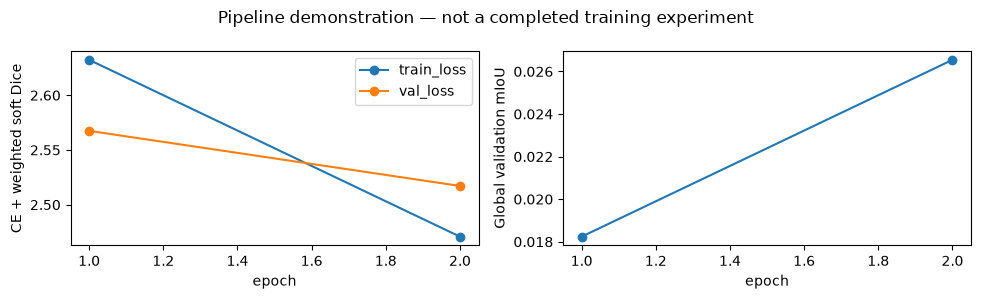

Loaded epoch 2 with validation mIoU 0.0265


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=axes[0])
history.plot(x="epoch", y="val_miou", marker="o", ax=axes[1], legend=False)
axes[0].set_ylabel("CE + weighted soft Dice")
axes[1].set_ylabel("Global validation mIoU")
fig.suptitle("Pipeline demonstration — not a completed training experiment")
fig.tight_layout()
fig.savefig(OUT / "learning_curves.png", dpi=110)
plt.show()

checkpoint = torch.load(OUT / "best.pt", map_location=device, weights_only=True)
assert checkpoint["class_names"] == CLASS_NAMES and checkpoint["settings"] == settings
model = ResidualASPP(checkpoint["settings"]["width"]).to(device)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print(f"Loaded epoch {checkpoint['epoch']} with validation mIoU {checkpoint['val_miou']:.4f}")

## 10. Class scores, confusion and regional results

Calculate scores from **global pixel counts**, not a mean of image-level scores. Also compare against a constant prediction chosen using the demonstration training images only.

The validation sample spans unseen training regions, but it is tiny and used for checkpoint selection. These are exploratory results, not final test performance. NaN class scores are left undefined rather than filled with a favourable value.

,model,mIoU,Dice
0,ResidualASPP demo,0.026546,0.047592
1,Always Developed Space,0.026631,0.043907


,class,support,IoU,Dice
0,Bareland,44042,0.000000,0.000000
1,Rangeland,255458,0.003398,0.006773
2,Developed Space,331977,0.000000,0.000000
3,Road,101881,0.065856,0.123574
4,Tree,172377,0.000000,0.000000
5,Water,191046,0.000000,0.000000
6,Agriculture Land,207574,0.000000,0.000000
7,Building,253886,0.143111,0.250389


,region,mIoU,valid_pixels
0,pisco,0.008029,262144
1,bielefeld,0.017039,262144
2,western,0.005915,247521
3,zachodniopomorskie,0.000482,262144
4,ica,0.135898,262144
5,chiclayo,0.045367,262144


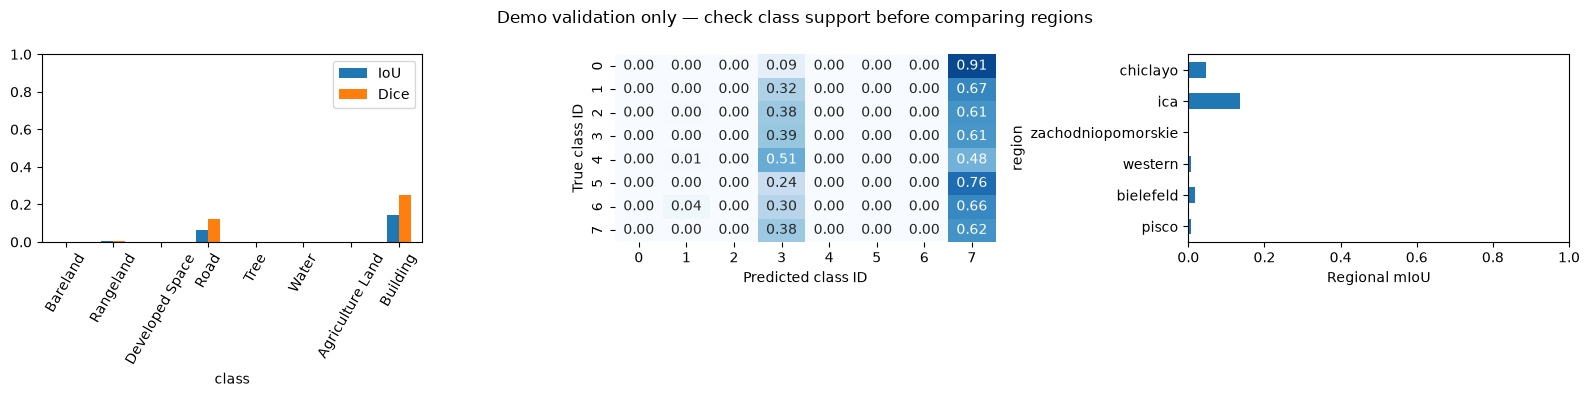

In [12]:
val_loss, counts, regional_counts = evaluate(model, val_pairs)
class_scores = metric_table(counts)
regional_scores = pd.DataFrame([
    {"region": region, "mIoU": metric_table(cm).IoU.mean(), "valid_pixels": int(cm.sum())}
    for region, cm in regional_counts.items()])
training_counts = torch.zeros(8, dtype=torch.int64)
for i in range(len(train_data)):
    _, target = train_data[i]
    training_counts += torch.bincount(target[target != IGNORE], minlength=8)
majority_class = int(training_counts.argmax())
baseline_counts = torch.zeros_like(counts)
baseline_counts[:, majority_class] = counts.sum(1)
summary = pd.DataFrame([
    {"model": "ResidualASPP demo", "mIoU": class_scores.IoU.mean(), "Dice": class_scores.Dice.mean()},
    {"model": f"Always {CLASS_NAMES[majority_class]}", "mIoU": metric_table(baseline_counts).IoU.mean(),
     "Dice": metric_table(baseline_counts).Dice.mean()}])
display(summary)
display(class_scores)
display(regional_scores)
class_scores.to_csv(OUT / "per_class.csv", index=False)
regional_scores.to_csv(OUT / "per_region.csv", index=False)
summary.to_csv(OUT / "model_and_constant_baseline.csv", index=False)
pd.DataFrame(counts.numpy(), index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUT / "confusion_counts.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
class_scores.set_index("class")[["IoU", "Dice"]].plot.bar(ax=axes[0], ylim=(0, 1), rot=60)
cm = counts.numpy()
normalized = np.divide(cm, cm.sum(1, keepdims=True), out=np.zeros_like(cm, dtype=float),
                       where=cm.sum(1, keepdims=True) > 0)
sns.heatmap(normalized, ax=axes[1], cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
            xticklabels=range(8), yticklabels=range(8), cbar=False)
axes[1].set(xlabel="Predicted class ID", ylabel="True class ID")
regional_scores.set_index("region").mIoU.plot.barh(ax=axes[2], xlim=(0, 1))
axes[2].set_xlabel("Regional mIoU")
fig.suptitle("Demo validation only — check class support before comparing regions")
fig.tight_layout()
fig.savefig(OUT / "validation_dashboard.png", dpi=110)
plt.show()

## 11. Predictions and uncertainty

Display a fixed validation example rather than choosing an attractive result. Black ground-truth pixels are ignored in the error map.

Entropy is low when one softmax probability dominates and high when probabilities are spread across classes. **Low entropy is not proof of accuracy or calibrated confidence.** The same helper can inspect any correctly preprocessed RGB tensor.

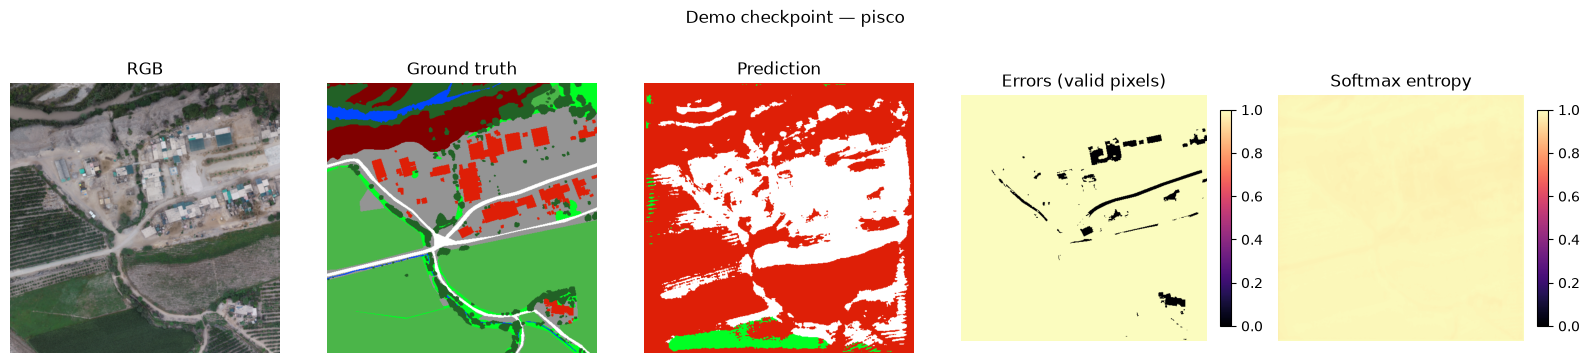

In [13]:
@torch.inference_mode()
def predict(model, image):
    probabilities = model(image[None].to(device)).softmax(1)[0].cpu()
    labels = probabilities.argmax(0)
    entropy = -(probabilities * probabilities.clamp_min(1e-12).log()).sum(0) / np.log(NUM_CLASSES)
    return labels, entropy

example_image, example_target = LandCoverDataset(val_pairs)[0]
prediction, entropy = predict(model, example_image)
errors = ((prediction != example_target) & (example_target != IGNORE)).numpy()
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
views = [example_image.permute(1, 2, 0), colorize(example_target), colorize(prediction), errors, entropy]
titles = ["RGB", "Ground truth", "Prediction", "Errors (valid pixels)", "Softmax entropy"]
for axis, view, title in zip(axes, views, titles):
    if view.ndim == 2:
        shown = axis.imshow(view, cmap="magma", vmin=0, vmax=1)
        fig.colorbar(shown, ax=axis, fraction=0.04)
    else:
        axis.imshow(view)
    axis.set_title(title)
    axis.axis("off")
fig.suptitle(f"Demo checkpoint — {val_pairs.iloc[0].region}")
fig.tight_layout()
fig.savefig(OUT / "prediction_and_errors.png", dpi=110)
plt.show()
Image.fromarray(prediction.numpy().astype(np.uint8)).save(OUT / "prediction_ids_0_to_7.png")
Image.fromarray(colorize(prediction)).save(OUT / "prediction_colors.png")

## 12. One simple explanation: occlusion

Choose a class and a fixed central ROI. Replace each of 16 image blocks with the image's mean RGB value and measure the change in that class's mean probability inside the ROI.

Red means removing that block reduces the score; blue means it increases the score. This measures sensitivity to an artificial input change, **not causal explanation or model quality**. The fill may create unrealistic images. Study this only alongside the error map and remember that this model has barely trained.

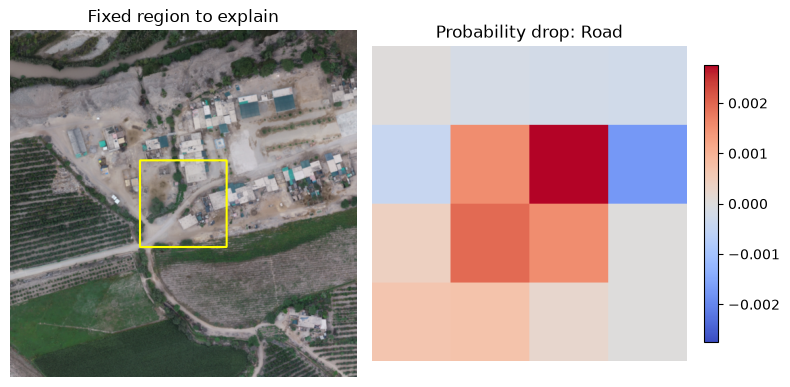

In [14]:
@torch.inference_mode()
def occlusion(model, image, class_id, roi, grid=4):
    assert roi.shape == image.shape[-2:] and roi.any()
    x = image[None].to(device)
    roi = roi.to(device)
    reference = model(x).softmax(1)[0, class_id][roi].mean()
    fill = x.mean((-2, -1), keepdim=True)
    heatmap = np.zeros(image.shape[-2:], dtype=np.float32)
    rows = np.linspace(0, image.shape[-2], grid + 1, dtype=int)
    cols = np.linspace(0, image.shape[-1], grid + 1, dtype=int)
    for y0, y1 in zip(rows[:-1], rows[1:]):
        for x0, x1 in zip(cols[:-1], cols[1:]):
            changed = x.clone()
            changed[:, :, y0:y1, x0:x1] = fill
            score = model(changed).softmax(1)[0, class_id][roi].mean()
            heatmap[y0:y1, x0:x1] = float(reference - score)
    return heatmap

roi = torch.zeros_like(example_target, dtype=torch.bool)
roi[192:320, 192:320] = True
class_id = int(torch.bincount(prediction[roi], minlength=8).argmax())
heatmap = occlusion(model, example_image, class_id, roi)
limit = max(float(np.abs(heatmap).max()), 1e-6)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(example_image.permute(1, 2, 0))
axes[0].contour(roi.numpy(), levels=[0.5], colors="yellow")
axes[0].set_title("Fixed region to explain")
shown = axes[1].imshow(heatmap, cmap="coolwarm", vmin=-limit, vmax=limit)
axes[1].set_title(f"Probability drop: {CLASS_NAMES[class_id]}")
for axis in axes:
    axis.axis("off")
fig.colorbar(shown, ax=axes[1], fraction=0.04)
fig.tight_layout()
fig.savefig(OUT / "occlusion.png", dpi=110)
plt.show()

## What to study and what remains

You now have one direct path: **data → residual model → loss → training → checkpoint → evaluation → visual inspection**.

Compare the architecture and training logic with `03_baseline.ipynb`, not the demonstration scores. The baseline has not yet undergone the same training/evaluation protocol, so a performance comparison would be misleading.

Before a full study:
- Complete the two-image overfit check and independent TorchMetrics metric verification.
- Reuse the **entire** saved train/validation partitions. The one-image-per-region sampling above is only for this demonstration.
- Agree on comparable budgets and report every difference: architecture, loss, normalization, parameters, epochs, time and seeds.
- Select on validation, then use `evaluate(model, test_pairs)` only after freezing the decision. Do not tune using test results.

**Saved evidence:** sampled manifest, settings/versions, best checkpoint, training history, confusion counts, per-class/per-region tables, predictions and figures. The previous notebook and its results are retained separately; its checkpoints belong to the previous U-Net architecture.

**References:** [DeepLabv3+ paper](https://arxiv.org/abs/1802.02611) for multiscale context and decoding; [PyTorch](https://docs.pytorch.org/docs/stable/nn.html) for the network blocks; [ReduceLROnPlateau](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html) for validation-driven scheduling; [OpenEarthMap labels/palette](https://github.com/bao18/open_earth_map/blob/main/open_earth_map/utils.py). The model here is a small custom adaptation, not the published architecture or its reported results.

**Verification:** run `.venv/Scripts/python.exe results/vibecode-test1/essential_revision/verify_pipeline.py`. Eight focused tests cover the new model, loss, metrics, alignment, checkpoints and occlusion. The unchanged `tests/test_vibecode_test1.py` targets the archived U-Net notebook and is not compatible with this revision; its default discovery currently fails during setup. It was left untouched to respect the requested file scope.
